# Задача: Анализ эффективности нового алгоритма рекомендаций в условиях асимметричного и зашумленного распределения
### Контекст:
Крупная стриминговая платформа (аналог YouTube или Twitch) разработала новый алгоритм рекомендаций контента (алгоритм B), который, как ожидается, должен увеличить среднее время просмотра на пользователя по сравнению со старым алгоритмом (A).

Было проведено A/B-тестирование:

- **Группа A (Контрольная)**: 5000 пользователей, старый алгоритм.

- **Группа B (Тестовая)**: 5000 пользователей, новый алгоритм.

По итогам двухнедельного теста вы собрали данные по ключевой метрике — **«Общее время просмотра на пользователя за тест (в минутах)»**.

**Данные и их особенности:**

**Не нормальность:** Распределение метрики в обеих группах сильно отличается от нормального. Оно имеет типичный для поведенческих данных "длинный хвост":

- Большинство пользователей смотрят немного (пик в районе 0-50 минут).

- Небольшая группа "супер-зрителей" смотрит очень много (сотни и тысячи минут), формируя длинный правый хвост распределения.

**Асимметрия влияния:** Новый алгоритм B целенаправленно меняет опыт именно активных пользователей, в то время как для "пассивных" зрителей разница неочевидна. Это означает, что различие между группами может быть не сдвигом всего распределения, а изменением в правом хвосте.

**Наличие выбросов:** В данных присутствуют экстремальные выбросы (например, пользователи, которые оставляли видео фоном на всю ночь).

Вам предоставлен датасет _ab_test_results.csv_ со следующими колонками:

 - _user_id_

 - _group (A или B)_

 - _total_watch_time_min_

### Задания:


- **Проведите тест Манна-Уитни (Mann-Whitney U test)**. Сформулируйте нулевую и альтернативную гипотезы. Интерпретируйте p-value. Можно ли на его основе сделать однозначный вывод о превосходстве алгоритма B?

- Чтобы исследовать "асимметричное влияние", проведите анализ разниц не только в центре распределения, но и в хвостах. **Рассчитайте и визуализируйте разницу между группами для 75-го, 90-го и 95-го процентилей**.

- **Сформулируйте итоговый вывод:**

    - Эффективен ли новый алгоритм B?

    - На какую именно группу пользователей он оказывает наибольшее влияние?

    - Какой метод анализа оказался наиболее информативным в данном случае и почему?

    - Дайте рекомендацию о возможности запуска алгоритма на всю аудиторию.



In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load CSV
df = pd.read_csv('data/ab_test_results.csv')

In [3]:
group_a_data = df[df['group'] == 'A']['total_watch_time_min']
group_b_data = df[df['group'] == 'B']['total_watch_time_min']

# Display summary statistics - описательная статистика
print("Dataset Summary:")
print(f"Total users: {len(df)}")
print(f"Group A: {len(df[df['group'] == 'A'])} users")
print(f"Group B: {len(df[df['group'] == 'B'])} users")

print("\nDescriptive Statistics by Group:")
print(df.groupby('group')['total_watch_time_min'].describe())

# анализ перцентилей (асимметричное влияние)
print("\nKey Percentiles by Group:")
percentiles = [0.75, 0.9, 0.95]
for p in percentiles:
    p_val = p * 100
    a_val = np.percentile(group_a_data, p_val)
    b_val = np.percentile(group_b_data, p_val)
    diff = b_val - a_val
    print(f"{p_val:.0f}th percentile: A={a_val:.1f}, B={b_val:.1f}, Difference={diff:.1f}")
# Test the differences
from scipy import stats
mw_stat, mw_p = stats.mannwhitneyu(
    group_b_data,
    group_a_data,
    alternative='two-sided'  # check есть ли различия между группами
)
print(f"\nMann-Whitney U Test two-sided: p-value = {mw_p:.6f}")

print("\nТест Манна-Уитни")
print("Гипотезы:")
print("H0 (нулевая): Распределения времени просмотра в группах A и B одинаковы")
print("H1 (альтернативная): Распределения времени просмотра в группах A и B различаются")

# Интерпретация p-value
alpha = 0.05
print(f"\nИнтерпретация (при alpha={alpha}):")
if mw_p < alpha:
    print(f"p-value ({mw_p:.4f}) < {alpha} -> есть основания отвергнуть нулевую гипотезу, значит : ")
    print("Статистически значимые различия между группами есть:")
    print("Какие именно - информации нет. Модификация теста.")
else:
    print(f"p-value ({mw_p:.4f}) >= {alpha} - нет оснований отвергать H0")
    print("Статистически значимых различий между группами нет.")

mw_stat_g, mw_p_g = stats.mannwhitneyu(
    group_b_data,
    group_a_data,
    alternative='greater'  # check if values в группе B > группы A
)

print(f"\nMann-Whitney U Test (greater) : p-value = {mw_p_g:.6f}")

Dataset Summary:
Total users: 10000
Group A: 5000 users
Group B: 5000 users

Descriptive Statistics by Group:
        count       mean         std  min        25%        50%        75%  \
group                                                                        
A      5000.0  56.347878  262.313288  0.0  14.729144  26.834960  44.946309   
B      5000.0  71.477408  408.519252  0.0  15.383838  27.352416  46.352279   

                max  
group                
A       8130.547119  
B      11670.621483  

Key Percentiles by Group:
75th percentile: A=44.9, B=46.4, Difference=1.4
90th percentile: A=71.5, B=76.2, Difference=4.7
95th percentile: A=119.3, B=153.6, Difference=34.3

Mann-Whitney U Test two-sided: p-value = 0.045342

Тест Манна-Уитни
Гипотезы:
H0 (нулевая): Распределения времени просмотра в группах A и B одинаковы
H1 (альтернативная): Распределения времени просмотра в группах A и B различаются

Интерпретация (при alpha=0.05):
p-value (0.0453) < 0.05 -> есть основания отвергну

In [4]:
# Интерпретация p-value
alpha = 0.05
print(f"\nИнтерпретация (при alpha={alpha}):")
if mw_p_g < alpha:
    print(f"p-value ({mw_p:.4f}) < {alpha} -> есть основания отвергнуть нулевую гипотезу, значит : ")
    print("Статистически значимые различия между группами есть:")
    print("Группа B показывает бОльшие значения времени просмотра, чем группа A.")
else:
    print(f"p-value ({mw_p:.4f}) >= {alpha} - нет оснований отвергать H0.")
    print("Статистически значимых различий между группами нет.")

print('\n Тест Манна-Уитни не проверяет равенство медиан, а проверяет вероятность, что случайное значение из одной группы больше/меньше случайного значения из другой группы.')
print(' Тест очень чувствителен к выбросам -> однозначный вывод о превосходстве одной из групп делать нельзя.')


Интерпретация (при alpha=0.05):
p-value (0.0453) < 0.05 -> есть основания отвергнуть нулевую гипотезу, значит : 
Статистически значимые различия между группами есть:
Группа B показывает бОльшие значения времени просмотра, чем группа A.

 Тест Манна-Уитни не проверяет равенство медиан, а проверяет вероятность, что случайное значение из одной группы больше/меньше случайного значения из другой группы.
 Тест очень чувствителен к выбросам -> однозначный вывод о превосходстве одной из групп делать нельзя.


In [5]:
# исследование "ассиметричного влияния" - анализ разниц в хвостах - более детальное рассмотрение результатов
percentiles = [75, 90, 95]
results = []
for p in percentiles:
    a_value = np.percentile(group_a_data, p)
    b_value = np.percentile(group_b_data, p)
    diff_abs = b_value - a_value
    diff_rel = (diff_abs / a_value * 100) if a_value > 0 else 0

    results.append({'Процентиль': f'{p}%','Группа A': round(a_value, 1),'Группа B': round(b_value, 1),'Разница (B-A)': round(diff_abs, 1),'Прирост %': round(diff_rel, 1)})

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

Процентиль  Группа A  Группа B  Разница (B-A)  Прирост %
       75%      44.9      46.4            1.4        3.1
       90%      71.5      76.2            4.7        6.6
       95%     119.3     153.6           34.3       28.7



 визуализация: 


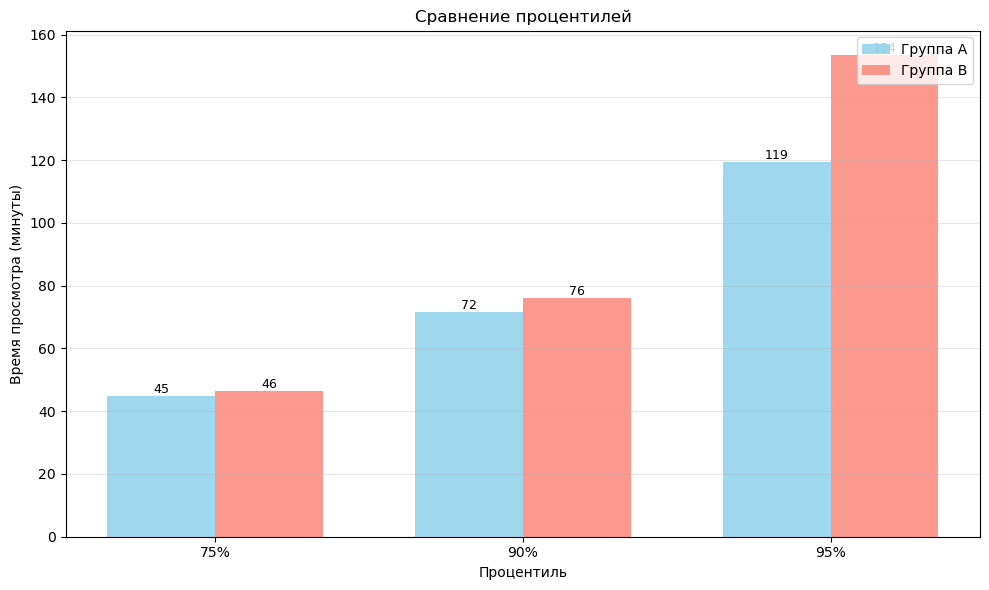

In [6]:
print("\n визуализация: ")
plt.figure(figsize=(10, 6))
percentile_labels = [f'{p}%' for p in percentiles]
a_values = [r['Группа A'] for r in results]
b_values = [r['Группа B'] for r in results]
growth_values = [r['Прирост %'] for r in results]

x = np.arange(len(percentiles))
width = 0.35

ax1 = plt.gca()

bars_a = ax1.bar(x - width/2, a_values, width,
                label='Группа A', color='skyblue', alpha=0.8)
bars_b = ax1.bar(x + width/2, b_values, width,
                label='Группа B', color='salmon', alpha=0.8)

ax1.set_xlabel('Процентиль')
ax1.set_ylabel('Время просмотра (минуты)', color='black')
ax1.set_title('Сравнение процентилей')
ax1.set_xticks(x)
ax1.set_xticklabels(percentile_labels)
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3, axis='y')


for bars in [bars_a, bars_b]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.0f}', ha='center', va='bottom', fontsize=9)


lines1, labels1 = ax1.get_legend_handles_labels()

ax1.legend(lines1, labels1, loc='upper right')

plt.tight_layout()
plt.show()

**Вывод**

1. Эффективен ли новый алгоритм B?

На основании теста Манна-Уитни (односторонний, p-value < 0.05) - получили, что новый алгоритм B статистически значимо увеличивает общее время просмотра по сравнению с алгоритмом A. Но величина эффекта не является равномерной для всех пользователей.

2. На какую именно группу пользователей он оказывает наибольшее влияние?

Анализ асимметричного влияния показывает:
- 75-й перцентиль (активные пользователи): прирост 3.1%
- 90-й перцентиль (очень активные): прирост 6.6%
- 95-й перцентиль (супер-зрители): прирост 28.7%

Чем выше активность пользователя, тем бОльший эффект от нового алгоритма. Максимальное улучшение наблюдается у топ-5% самых вовлеченных зрителей (95-й перцентиль).

3. Какой метод анализа оказался наиболее информативным в данном случае и почему?

Анализ асимметричного влияния через сравнение процентилей.

**Тест Манна-Уитни** показывает, что есть статистически значимые различия между группами A и B, и даже в "какую сторону". Но не показывает для какого сегмента пользователей из группы новый алгоритм рекомендаций работает на увеличение просмотра.

А **анализ процентилей** (75-го, 90-го, 95-го) обнаружил асимметричную природу влияния алгоритма, оценил эффект для разных сегментов пользователей. И можно констатировать : наибольшая польза от внедрения нового алгоритма - для супер-активных пользователей (скорее всего самой ценной аудитории платформы).


4. Рекомендация о возможности запуска алгоритма на всю аудиторию.

Новый алгоритм можно запускать на всю аудиторию. Но сам запуск надо проводить поэтапно, отслеживая не только время просмотра, но и удовлетворённость пользователей + контроль оттока. Динамический мониторинг поможет минимизировать риски - в случае неудачи вернуться к старому алгоритму без большой потери пользователей.